In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.neighbors import NearestNeighbors
from mpl_toolkits.mplot3d import Axes3D

##Key task: Performing K-nearest neighbours on data points of a frame, get direction vectors,calculate geodesics & depth and performing 3D reconstruction of keypoints with geodesic distance and depth from multiple sequences(hulk, seq 23, seq 27)

#Seq 27

##Data Loading

## Data Points

In [ ]:
url = "https://git.zib.de/asengupta/sose2025_geometric_cv/-/raw/49b3ec7dab539b18f7c0353e99f528fd5ef17ed0/data/Seq_27/Points2D_1.txt"

data_raw = pd.read_csv(url, sep=',', header=None)
data_raw = data_raw.values
print(data_raw)


[[ 201  261  261  261  321  321  321  341  361  381  401  401  401  421
   421  421  421  421  441  441  461  461  481  561  561  761  901  921
   981  210  230  250  250  250  270  270  290  310  330  350  370  390
   390  410  410  410  410  430  450  490  510  530  550  550  570  570
   590  610  650  850  870  930  970  970  990 1010 1030 1050 1110]
 [ 661  461  541  861  561  921  981  661  421  921  841  901  941  641
   701  741  821  861  641  901  541  601  881  761  901  641  961  921
   761  670  650  450  850  870  850  870  650  330  510  910  430  690
   970  470  590  790  870  650  650  530  730  770  770  790  810  830
   830  690  870  190  150  970  710  970  750  910  950  930  650]]


In [ ]:
data_raw.shape

(2, 69)

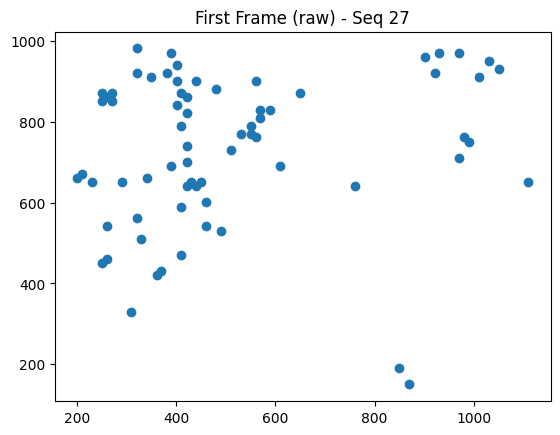

In [ ]:
plt.scatter(data_raw[0],data_raw[1])
plt.title("First Frame (raw) - Seq 27")
plt.show()

In [ ]:
url = "https://git.zib.de/asengupta/sose2025_geometric_cv/-/raw/49b3ec7dab539b18f7c0353e99f528fd5ef17ed0/data/Seq_27"
ids = list(range(1, 142))

points =[]

for i in ids:
    temp = f"{url}/Points2D_{i}.txt"
    data_raw = pd.read_csv(temp, sep=',', header=None).values
    keypoints = data_raw.T
    points.append(keypoints)



In [ ]:
print(len(points))
print(points[140].shape) #index of 141th frame  is 140
#141 frames with 69 data points each

141
(69, 2)


In [ ]:
#basically create a 3d matrix by stacking 2d frame array list
points_frame = np.stack(points, axis=0)

## Camera matrix K

In [ ]:
k_url = f"{url}/K.txt"
K = pd.read_csv(k_url, sep=',', header=None).values


print(K)
Kin = np.linalg.inv(K)

[[727.1851   0.     738.1817]
 [  0.     728.5954 537.4003]
 [  0.       0.       1.    ]]


## Knn for first frame

In [ ]:
points1 = points_frame[0]

k = 7 #or other, i like 4
neigh = NearestNeighbors(n_neighbors=k+1).fit(points1)
distances, indices = neigh.kneighbors(points1)

In [ ]:
#first neigh is myself and next is the nearest number, so filter out myself
neighbors = indices[:,1:]
distances = distances[:,1:]



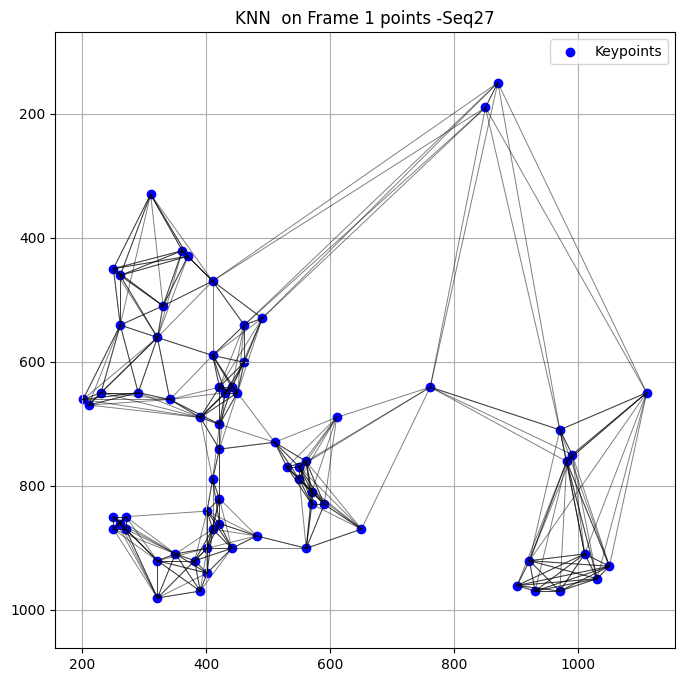

In [ ]:
plt.figure(figsize=(8, 8))
plt.scatter(points1[:, 0], points1[:, 1], c='blue', label='Keypoints')

for i in range(len(points1)):
    for j in neighbors[i]:
        pt1 = points1[i]
        pt2 = points1[j]
        plt.plot([pt1[0], pt2[0]], [pt1[1], pt2[1]], 'k-', alpha=0.5, linewidth=0.7)

plt.title("KNN  on Frame 1 points -Seq27")
plt.gca().invert_yaxis()
plt.axis('equal')
plt.grid(True)
plt.legend()
plt.show()

## Geo. dist. + Depth

## Sightlines
The calculation of the direction vectors (sightlines) is done in the following loop

In [ ]:
n_frames, n_points, _ = points_frame.shape


sightl = np.zeros((n_frames, n_points, 3))
#141 matrices with 69x3 rowXcolumn

In [ ]:
#sightlines
for i in range(n_frames):

    temp = np.hstack([points_frame[i], np.ones((n_points, 1))])
    # basically adds to 69x2 (all point pairs(u,v) a 69x1 vector -> result 69x3 vector (u,v,1))

    temp = np.dot(temp, Kin.T)
    # matrix multiplication of the pseudo 3d point with the transpose camera intrinsic matrix

    sightl[i] = temp/np.linalg.norm(temp, axis=1, keepdims=True)
    # normalize the direction vectors (temp) to a unit vector so that the length can then be actually added by multiplying with depth

## Eq7 for geod. from slides


In [ ]:
# eq 7?

def compute_geo(depths, sightl, neighbors, fram, ps):

    geo = np.zeros((ps, ps))

    for j in range(ps):

        for q in neighbors[j]:

            sum= 0

            for i in range(fram):

                dj = depths[i, j] #i frame, j keypoint
                dq = depths[i, q]

                vj = sightl[i, j]
                v_q = sightl[i, q]

                # Equation 7 term
                dotpr = np.dot(vj, v_q)
                term = dj**2 + dq**2 - 2 * dj * dq * dotpr
                sum = sum + term

            geo[j, q] = np.sqrt(sum /fram)

    #sym.mat
    for j in range(ps):

        for q in neighbors[j]:

            geo[q, j] = geo[j, q]

    return geo

## Eq11 for depth given from slides

In [ ]:
#eq 11?

def compute_depths(depths, sightl, geo, neighbors,fram,ps, lam=0.1):
    new_depths = depths.copy()

    for i in range(fram):
        for j in range(ps):

            sum =0

            for q in neighbors[j]:

                djq=geo[j, q]

                delj= depths[i, j]
                delq=depths[i, q]

                pj =sightl[i, j]
                pq = sightl[i, q]

                dotpro= np.dot(pj, pq)

                #put e11 together
                eq= (2 *(delj**3)- 6 *(delj**2)*delq*dotpro + 2* delj * (delq**2) * (1 + 2 * (dotpro**2)) - 2*delq*dotpro*((delq**2) - (djq**2)))
                sum= sum+ eq

            update = -lam + (2*sum)
            new_depths[i, j] -= 0.01 * update #learning rate caus enum. issues

    return new_depths



## Iterative until converge/ run out of iterations

In [ ]:
#ini depth w. 1
depths = np.ones((n_frames, n_points))

#ini out put for geodesics
geo = np.zeros((n_points, n_points))

In [ ]:
max_iter = 42
convergence =0.0001

for r in range( max_iter):

    geo = compute_geo(depths,  sightl, neighbors,n_frames,n_points)
    geo = geo/np.sqrt( np.sum(geo**2)) #normalize
    new_depths = compute_depths(depths, sightl, geo, neighbors,n_frames,n_points  )

    delta_change=abs(np.linalg.norm(new_depths - depths))
    if delta_change < convergence:
        break

    depths = new_depths

## Reconstruct

In [ ]:
points_3d = depths[..., np.newaxis] *sightl

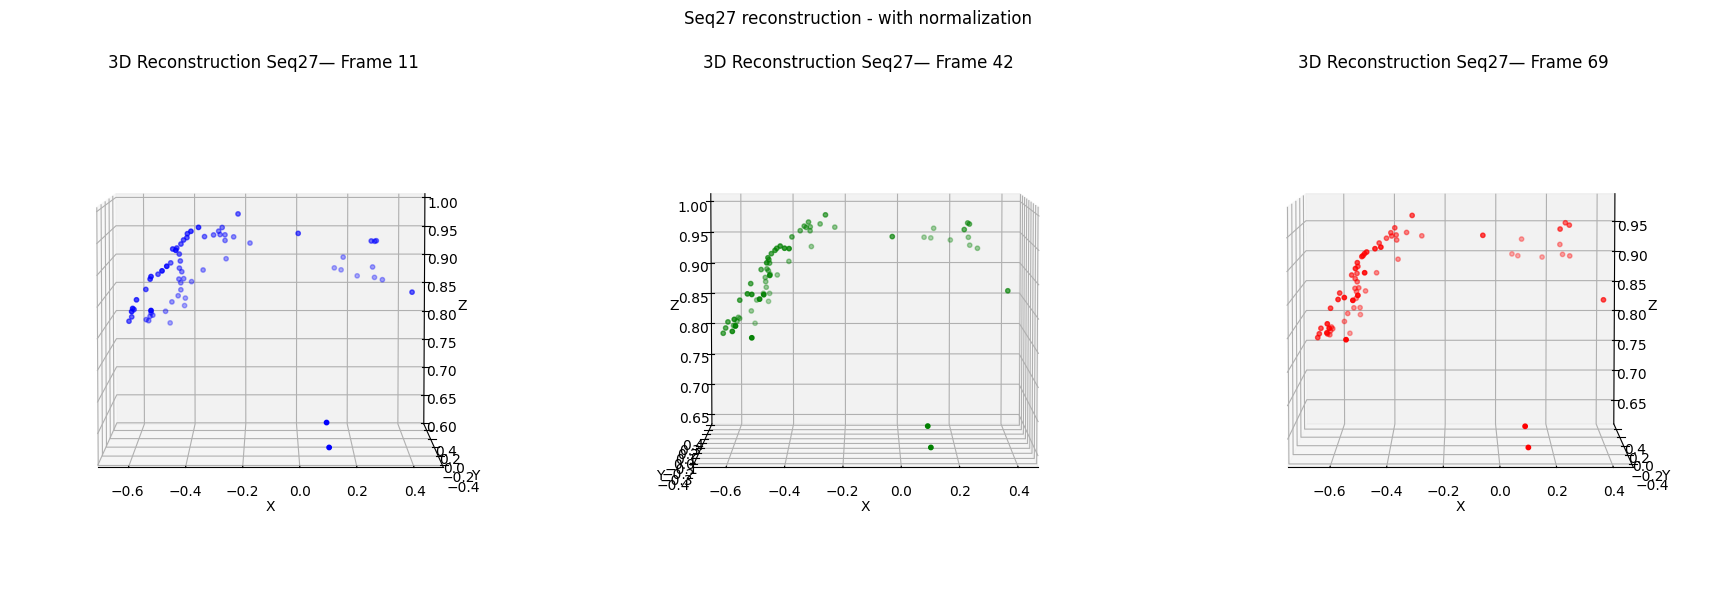

In [ ]:


frame_indices = [11, 42, 69]
colors = ['blue', 'green', 'red']


fig = plt.figure(figsize=(18, 6))

for i, frame_idx in enumerate(frame_indices):
    ax = fig.add_subplot(1, 3, i+1, projection='3d')
    X = points_3d[frame_idx]

    ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=colors[i], s=10)
    ax.set_title(f"3D Reconstruction Seq27— Frame {frame_idx}")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.view_init(elev=5, azim=270)  #angle

fig.suptitle("Seq27 reconstruction - with normalization")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()



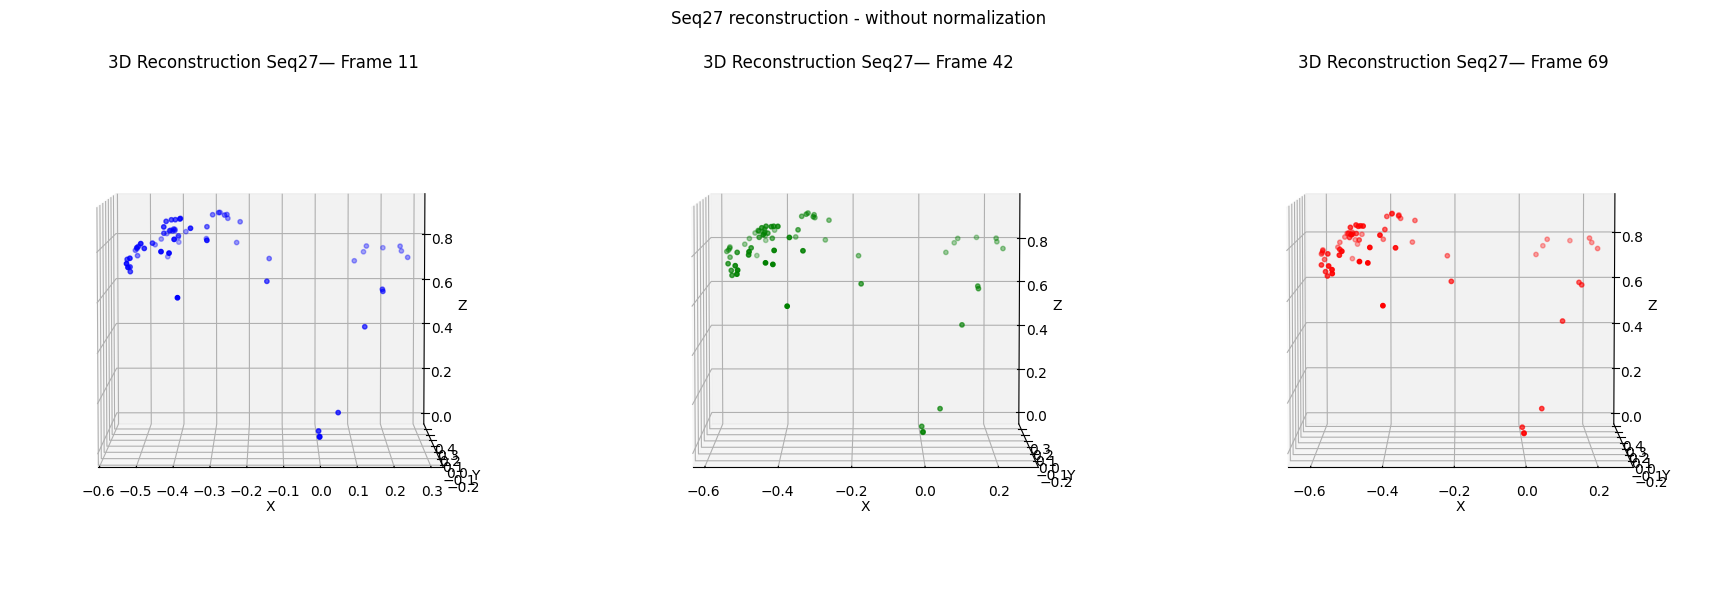

In [ ]:
#ini depth w. 1
depths = np.ones((n_frames, n_points))

#ini out put for geodesics
geo = np.zeros((n_points, n_points))


max_iter = 42
convergence =0.0001

for r in range( max_iter):

    geo = compute_geo(depths,  sightl, neighbors,n_frames,n_points)
##no normalisation here
    new_depths = compute_depths(depths, sightl, geo, neighbors,n_frames,n_points  )

    delta_change=abs(np.linalg.norm(new_depths - depths))
    if delta_change < convergence:
        break

    depths = new_depths

points_3d = depths[..., np.newaxis] *sightl


frame_indices = [11, 42, 69]
colors = ['blue', 'green', 'red']


fig = plt.figure(figsize=(18, 6))

for i, frame_idx in enumerate(frame_indices):
    ax = fig.add_subplot(1, 3, i+1, projection='3d')
    X = points_3d[frame_idx]

    ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=colors[i], s=10)
    ax.set_title(f"3D Reconstruction Seq27— Frame {frame_idx}")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.view_init(elev=5, azim=270)  #angle

fig.suptitle("Seq27 reconstruction - without normalization")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# Hulk data

## Data and 2d data points(x,y)

In [ ]:
url2 = "https://git.zib.de/asengupta/sose2025_geometric_cv/-/raw/49b3ec7dab539b18f7c0353e99f528fd5ef17ed0/data/Hulk/Points2D_1.txt"

data_raw = pd.read_csv(url2, sep=',', header=None)
data_raw = data_raw.values
print(data_raw)



[[2701 2341 3061 1981 2881 2701 1801 2341 2521 1801 2341 2701 3241 3241
  2881 2521 2161 1981 3421 3061 1801 2701 3241 3241 2881 3061 2341 2701
  3421 1801 2881 2881 1801 2881 3061 2701 3421 3241 2521 2701 2881 1801
  3061 3241 1981 3061 2701 2521 2341 2341 2881 2161 2161 2881 2881 2161
  3241 1981 2521 1801 1981 1801 3241 1801 3241 2341 1981 1801 3421 3061
  1801 2341 2701]
 [ 901 2341  721 1621  541 2521 2701  721 1441 2341 1981 1621 1081 1441
  1441  721  541  541  541 1081 2521 1981 2161  541 2341 1261 1261 1801
  2701 1801  901 1981 1981 2701 2521  541 2341 2341  541 1081 1801  901
   541  901 2521 2161  721 1261 1801 2701 2161 1441  901 1261 1621 2341
  1981 2341 2521 1621 1981 1081 1621 2161 2521  541 1081 1441  721 1621
   721 2161 2161]]


In [ ]:
data_raw.shape

(2, 73)

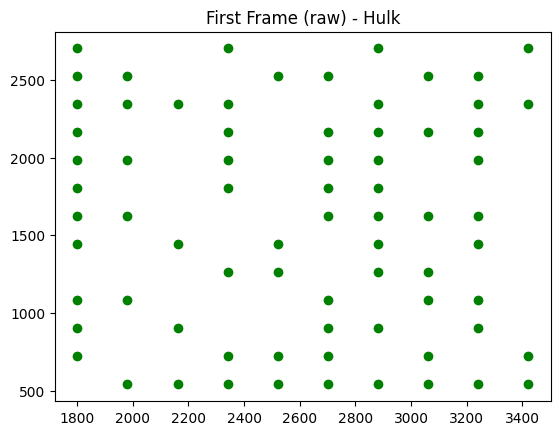

In [ ]:
plt.scatter(data_raw[0],data_raw[1],color="green")
plt.title("First Frame (raw) - Hulk")
plt.show()

In [ ]:
url2 = "https://git.zib.de/asengupta/sose2025_geometric_cv/-/raw/49b3ec7dab539b18f7c0353e99f528fd5ef17ed0/data/Hulk"
ids = list(range(1, 11))

points_hulk = []

for i in ids:
    temp = f"{url2}/Points2D_{i}.txt"
    data_raw = pd.read_csv(temp, sep=',', header=None).values
    keypoints = data_raw.T
    points_hulk.append(keypoints)

In [ ]:
print(len(points_hulk))
print(points_hulk[9].shape)

10
(73, 2)


##K matrix- hulk data

[[fx, 0, cx],
 [0, fy, cy],
 [0, 0, 1]]- inverse

In [ ]:
k_url = f"{url2}/K.txt"
K_hulk = pd.read_csv(k_url, sep=',', header=None).values

print(K_hulk)
K_hulk_in = np.linalg.inv(K_hulk) #inverse of this matrix

[[3.78485896e+03 0.00000000e+00 2.51515355e+03]
 [0.00000000e+00 3.78380130e+03 1.64113389e+03]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]


##knn in hulk data frame 1

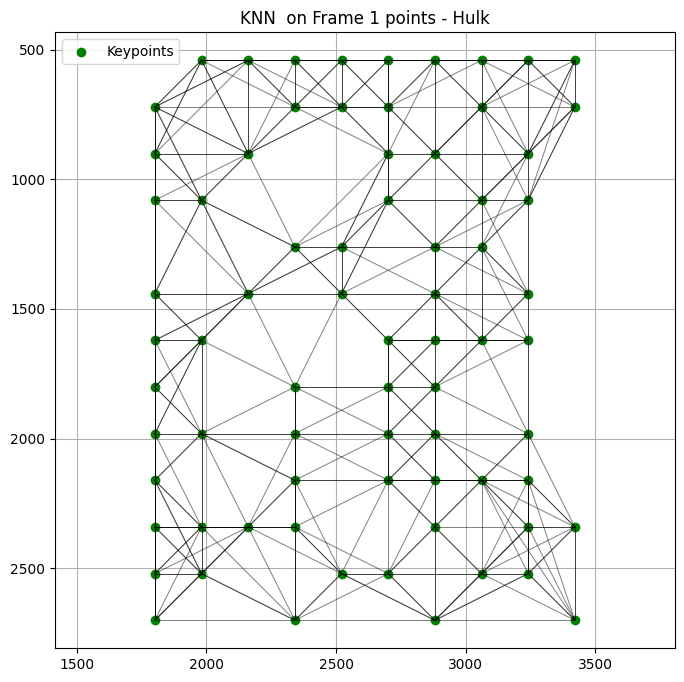

In [ ]:
points_hulk_frame = np.stack(points_hulk, axis=0)
points1 = points_hulk_frame[0]

k = 7
neigh_hulk = NearestNeighbors(n_neighbors=k + 1).fit(points1)
distances_hulk, indices_hulk = neigh_hulk.kneighbors(points1)

#first neigh is myself and next is the nearest number
neighbors_hulk = indices_hulk[:, 1:]
distances_hulk = distances_hulk[:, 1:]


plt.figure(figsize=(8, 8))
plt.scatter(points1[:, 0], points1[:, 1], c='green', label='Keypoints')

for i in range(len(points1)):
    for j in neighbors_hulk[i]:
        pt1 = points1[i]
        pt2 = points1[j]
        plt.plot([pt1[0], pt2[0]], [pt1[1], pt2[1]], 'k-', alpha=0.5, linewidth=0.7)

plt.title("KNN  on Frame 1 points - Hulk")
plt.gca().invert_yaxis()
plt.axis('equal')
plt.grid(True)
plt.legend()
plt.show()


##Sightlines

In [ ]:
n_frames_hulk,n_points_hulk,_ = points_hulk_frame.shape


sightl_hulk = np.zeros((n_frames_hulk, n_points_hulk,3))

for i in range(n_frames_hulk):

    temp = np.hstack( [points_hulk_frame[i], np.ones((n_points_hulk, 1))])
    temp = np.dot( temp, K_hulk_in.T)

    sightl_hulk[i] = temp /np.linalg.norm(temp,axis=1, keepdims=True) #unit vector normalisation for using them with depth multiplication

##using equation 7 and 11 for geodesic dist and depth

In [ ]:
#hulk data provides ini depths -using them

depths_h_temp= []

url = "https://git.zib.de/asengupta/sose2025_geometric_cv/-/raw/49b3ec7dab539b18f7c0353e99f528fd5ef17ed0/data/HulkInitialisation"

for i in range(1, n_frames_hulk + 1):
    ini = f"{url}/Points3D_init_{i}.txt"
    dep = pd.read_csv(ini, sep=',', header=None).values.flatten()
    depths_h_temp.append(dep)

depths_hulk = np.stack(depths_h_temp,axis=0)

Iterating until convergence

In [ ]:
#ini out put for geodesics
geo_hulk = np.zeros((n_points, n_points))

max_iter = 42
convergence =0.0001

for r in range( max_iter):

    geo_hulk = compute_geo(depths_hulk,  sightl_hulk, neighbors_hulk,n_frames_hulk, n_points_hulk)
    #geo_hulk = geo_hulk/np.sqrt( np.sum(geo_hulk**2)) #normalize , maybe not needed
    new_depths = compute_depths(depths_hulk, sightl_hulk,geo_hulk, neighbors_hulk ,n_frames_hulk,n_points_hulk  )

    delta_change=abs(np.linalg.norm(new_depths - depths_hulk))
    if delta_change < convergence:
        break

    depths_hulk = new_depths

##3D reconstruction

In [ ]:
points_3d = depths_hulk[..., np.newaxis] *sightl_hulk

In [ ]:
#ground truth
ids = list(range(1, 11))
gt = []
gt_url ="https://git.zib.de/asengupta/sose2025_geometric_cv/-/raw/49b3ec7dab539b18f7c0353e99f528fd5ef17ed0/data/HulkGT"

for idx in ids:
    temp = f"{gt_url}/Points3D_gt_{idx}.txt"
    keypoints = pd.read_csv(temp, sep=',', header=None).values
    gt.append(keypoints.T)

gt= np.stack(gt, axis=0)
print(gt.shape)

(10, 73, 3)


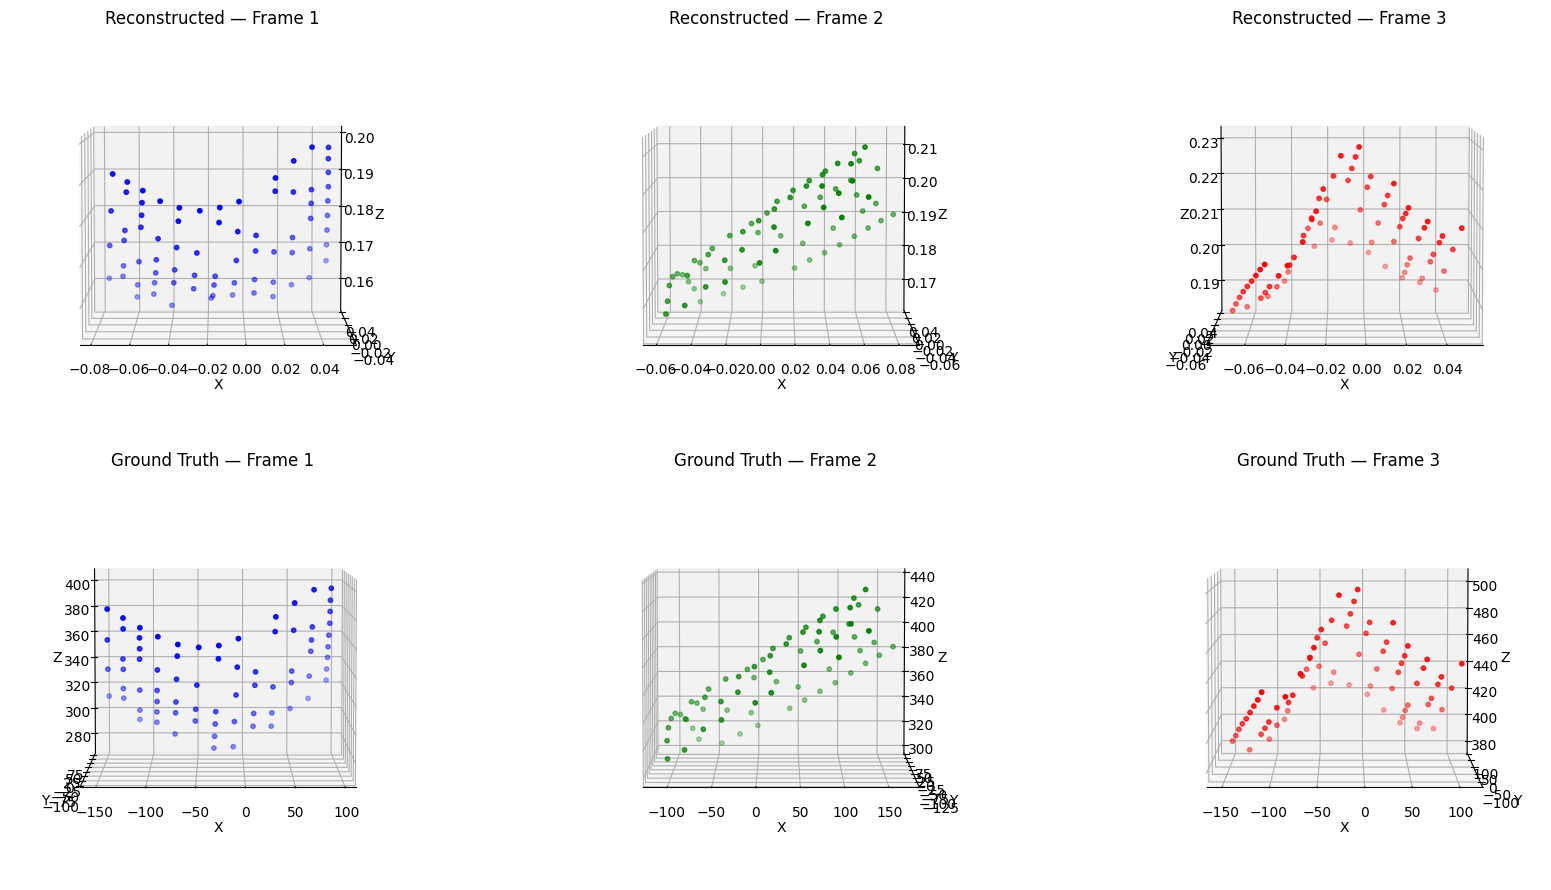

In [ ]:
frame_indices = [1, 2, 3]
colors = ['blue', 'green', 'red']


fig = plt.figure(figsize=(18, 9))

for i, frame_idx in enumerate(frame_indices):
    #reconstr
    ax1 = fig.add_subplot(2, 3, i + 1, projection='3d')
    X = points_3d[frame_idx]
    ax1.scatter(X[:, 0], X[:, 1], X[:, 2], c=colors[i], s=10)
    ax1.set_title(f"Reconstructed — Frame {frame_idx}")
    ax1.set_xlabel("X")
    ax1.set_ylabel("Y")
    ax1.set_zlabel("Z")
    ax1.view_init(elev=5, azim=270)

    #ground truth
    ax2 = fig.add_subplot(2, 3, i + 4, projection='3d')
    gtplt = gt[frame_idx]
    ax2.scatter(gtplt[:, 0], gtplt[:, 1], gtplt[:, 2], c=colors[i], s=10)
    ax2.set_title(f"Ground Truth — Frame {frame_idx}")
    ax2.set_xlabel("X")
    ax2.set_ylabel("Y")
    ax2.set_zlabel("Z")
    ax2.view_init(elev=5, azim=270)

plt.tight_layout()


plt.show()

#Seq 23

##Data points(2d)

In [ ]:
url3 = "https://git.zib.de/asengupta/sose2025_geometric_cv/-/raw/49b3ec7dab539b18f7c0353e99f528fd5ef17ed0/data/Seq_23/Points2D_1.txt"

data_raw = pd.read_csv(url3, sep=',', header=None)
data_raw = data_raw.values
print(data_raw)

[[ 181  201  201  201  221  241  241  241  241  261  261  261  281  301
   301  301  301  301  321  321  321  321  321  341  341  361  361  361
   381  381  381  401  401  421  421  421  441  441  441  441  441  461
   461  461  461  461  461  461  481  481  481  481  481  481  501  501
   501  501  501  501  501  521  521  521  521  521  541  541  541  561
   561  561  561  561  561  561  581  581  581  581  581  601  601  601
   601  621  621  621  641  641  641  641  661  661  681  701  701  701
   721  721  741  741  741  741  781  801  841  841  841  861  861  861
   861  861  881  881  881  881  881  901  901  901  901  921  921  921
   921  921  941  941  941  941  941  941  941  961  961  961  981  981
   981  981  981  981  981 1001 1001 1001 1001 1001 1001 1001 1001 1001
  1021 1021 1021 1021 1041 1041 1041 1041 1041 1061 1061 1061 1061 1081
  1081 1081 1081 1081 1081 1081 1101 1101 1101 1101 1101 1101 1101 1101
  1101 1121 1121 1121 1121 1121 1141 1141 1141 1141 1161 1161 11

In [ ]:
data_raw.shape

(2, 227)

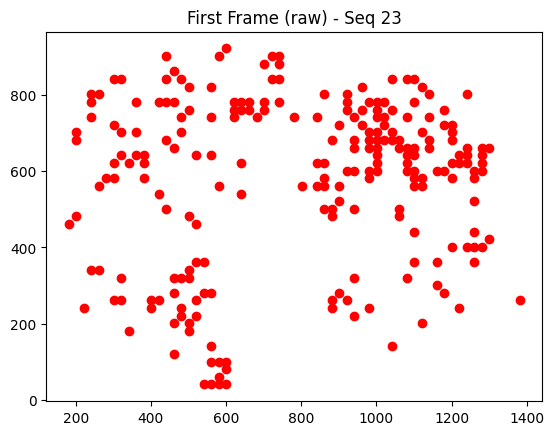

In [ ]:
plt.scatter(data_raw[0],data_raw[1],color="red")
plt.title("First Frame (raw) - Seq 23")
plt.show()

In [ ]:
url3 = "https://git.zib.de/asengupta/sose2025_geometric_cv/-/raw/49b3ec7dab539b18f7c0353e99f528fd5ef17ed0/data/Seq_23"
ids = list(range(1, 71))

points23 =[]

for i in ids:
    temp = f"{url3}/Points2D_{i}.txt"
    data_raw = pd.read_csv(temp, sep=',', header=None).values
    keypoints = data_raw.T
    points23.append(keypoints)

In [ ]:
print(len(points23))
print(points23[69].shape)

70
(227, 2)


##K matrix for camera intrinsic matrix 3x3

In [ ]:
k_url = f"{url3}/K.txt"
K23 = pd.read_csv(k_url, sep=',', header=None).values


print(K23)
K23_in = np.linalg.inv(K23)

[[785.2521   0.     741.1905]
 [  0.     786.6768 542.8783]
 [  0.       0.       1.    ]]


##Knn for first frame in seq 23

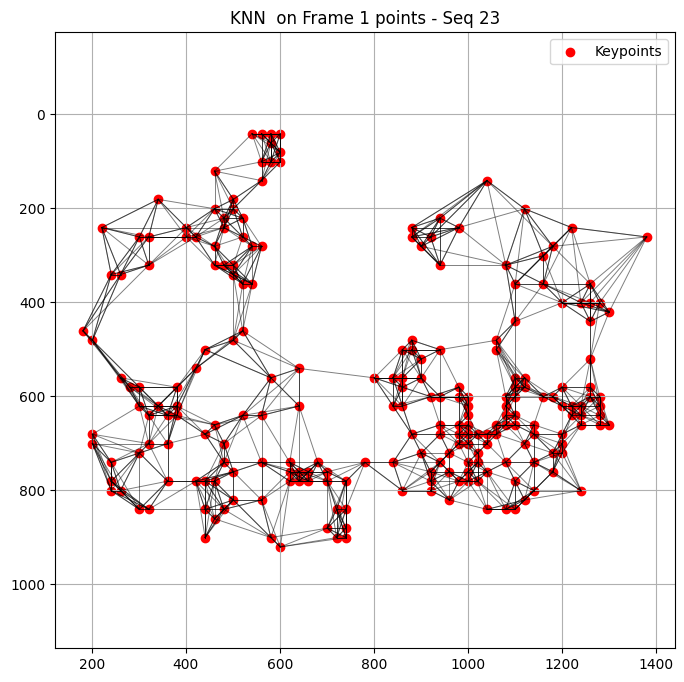

In [ ]:
points23_frame = np.stack(points23, axis=0)
points1_seq23 = points23_frame[0]

k = 7
neigh23 = NearestNeighbors(n_neighbors=k + 1).fit(points1_seq23)
distances23,indices23 = neigh23.kneighbors(points1_seq23)

neighbors23 = indices23[:, 1:]
distances23 = distances23[:, 1:]

plt.figure(figsize=(8, 8))
plt.scatter(points1_seq23[:, 0], points1_seq23[:, 1], c='red', label='Keypoints')

for i in range(len(points1_seq23)):
    for j in neighbors23[i]:
        pt1 = points1_seq23[i]
        pt2 = points1_seq23[j]
        plt.plot([pt1[0], pt2[0]], [pt1[1], pt2[1]], 'k-', alpha=0.5, linewidth=0.7)

plt.title("KNN  on Frame 1 points - Seq 23")
plt.gca().invert_yaxis()
plt.axis('equal')
plt.grid(True)
plt.legend()
plt.show()

##Sightlines(direction vectors)

In [ ]:
n_frames23,n_points23, _ = points23_frame.shape


sightl23 = np.zeros((n_frames23,n_points23,3))

Sightlines are unit vectors that point from the camera's optical center to the corresponding 2D keypoint in the image plane, projected into 3D space.

In [ ]:
for i in range(n_frames23):

    temp = np.hstack([points23_frame[i], np.ones((n_points23, 1))])
    temp = np.dot(temp, K23_in.T)

    sightl23[i] = temp/np.linalg.norm(temp, axis=1, keepdims=True)

Iterate until convergence

In [ ]:
#ini depth w. 1
depths23 =np.ones((n_frames23,n_points23))

#ini out put for depth
geo23 =np.zeros((n_points23,n_points23))

max_iter = 42
convergence =0.0001

for r in range( max_iter):

    geo23 = compute_geo(depths23,  sightl23, neighbors23,n_frames23,n_points23)
    geo23 = geo23/np.sqrt( np.sum(geo23**2)) #normalize
    new_depths = compute_depths(depths23, sightl23, geo23, neighbors23,n_frames23,n_points23  )

    delta_change=abs(np.linalg.norm(new_depths - depths23))
    if delta_change < convergence:
        break

    depths23 = new_depths

##3D Reconstruction

In [ ]:
points_3d = depths23[..., np.newaxis] *sightl23

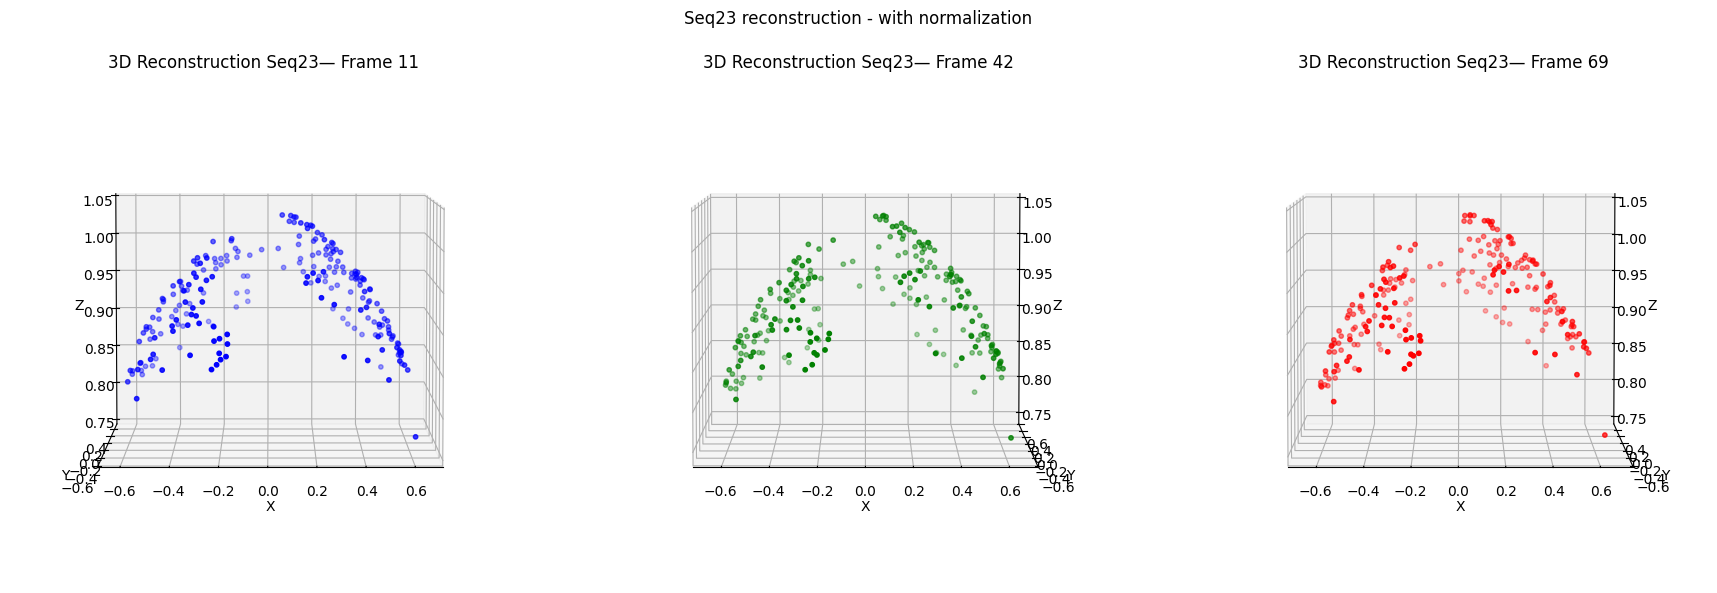

In [ ]:

frame_indices = [11, 42, 69]
colors = ['blue', 'green', 'red']


fig = plt.figure(figsize=(18, 6))

for i, frame_idx in enumerate(frame_indices):
    ax = fig.add_subplot(1, 3, i+1, projection='3d')
    X = points_3d[frame_idx]

    ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=colors[i], s=10)
    ax.set_title(f"3D Reconstruction Seq23— Frame {frame_idx}")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.view_init(elev=5, azim=270)  #angle


fig.suptitle("Seq23 reconstruction - with normalization")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

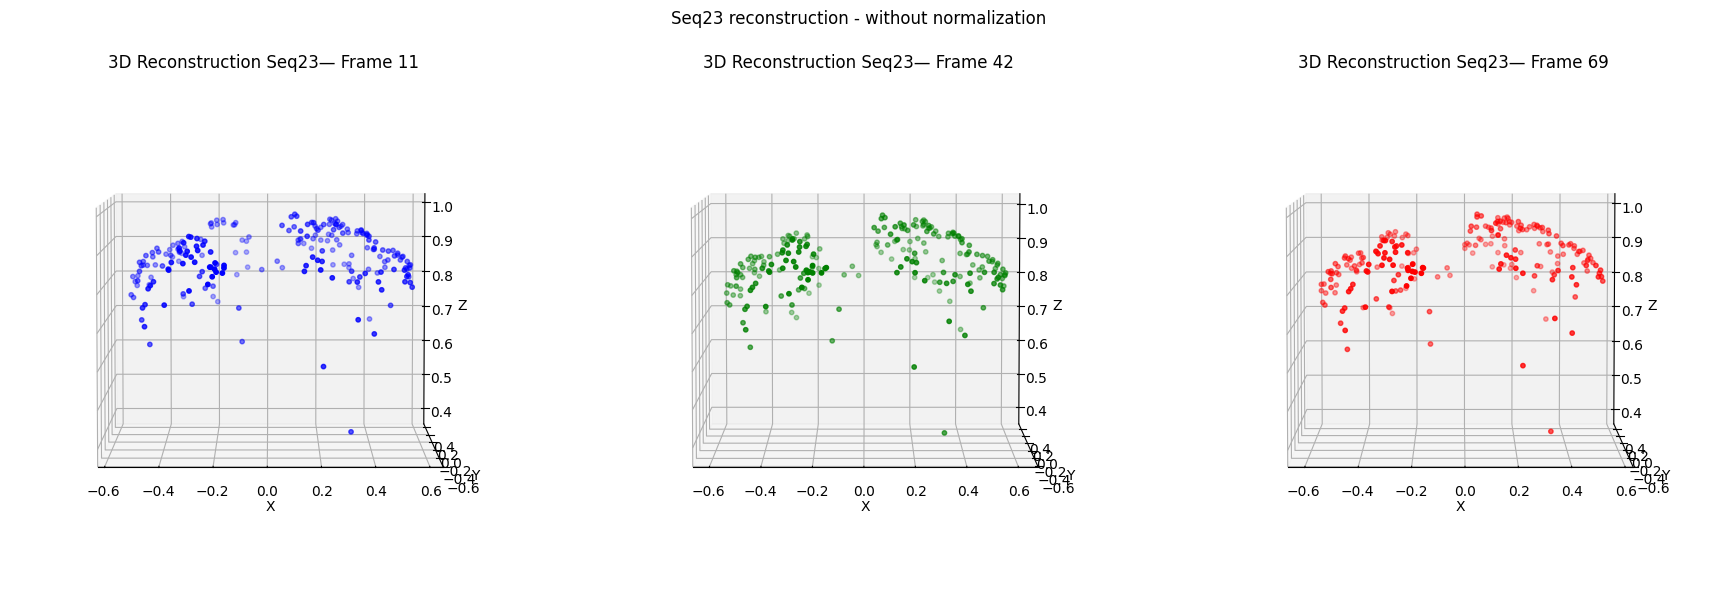

In [ ]:
#ini depth w. 1
depths23 =np.ones((n_frames23,n_points23))

#ini out put for depth
geo23 =np.zeros((n_points23,n_points23))

max_iter = 42
convergence =0.0001

for r in range( max_iter):

    geo23 = compute_geo(depths23,  sightl23, neighbors23,n_frames23,n_points23)

    new_depths = compute_depths(depths23, sightl23, geo23, neighbors23,n_frames23,n_points23  )

    delta_change=abs(np.linalg.norm(new_depths - depths23))
    if delta_change < convergence:
        break

    depths23 = new_depths

points_3d = depths23[..., np.newaxis] *sightl23

frame_indices = [11, 42, 69]
colors = ['blue', 'green', 'red']


fig = plt.figure(figsize=(18, 6))

for i, frame_idx in enumerate(frame_indices):
    ax = fig.add_subplot(1, 3, i+1, projection='3d')
    X = points_3d[frame_idx]

    ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=colors[i], s=10)
    ax.set_title(f"3D Reconstruction Seq23— Frame {frame_idx}")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.view_init(elev=5, azim=270)  #angle


fig.suptitle("Seq23 reconstruction - without normalization")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()